In [1]:
import sys, time
sys.path.insert(0, "../examples")
import numpy as np, jax, jax.numpy as jnp, scipy.optimize
import matplotlib.pyplot as plt
import gebtaero_jax as gx
from gebtaero_jax import tracking as tk
from crm_wing import CRMWing, baseline_thickness, planform, SEMI_SPAN, SWEEP_LE, FRONT_SPAR, REAR_SPAR

## 1. CRM-like wing model
Planform: approximate public CRM values (semi-span 29.38 m, quarter-chord sweep 35°, Yehudi break at 37 % semi-span, chords ≈ 13.6 / 7.3 / 2.7 m).
Structure: a **simplified** single-cell aluminium wingbox between 15 % and 65 % of the trapezoidal chord, swept along its centre line, plus
non-structural mass (fuel, ribs, edges, systems, 60 kg/m² with its CG at 45 % chord). This is *not* the uCRM finite-element model; numbers
are illustrative. Design variables: skin and spar-web thickness of each of the $N=16$ spanwise segments, $n_x=32$.
The flutter requirement uses sea-level density and incompressible strip theory (Peters' inflow), i.e. no transonic effects.

baseline wingbox mass = 12482 kg, total semi-span mass = 24850 kg


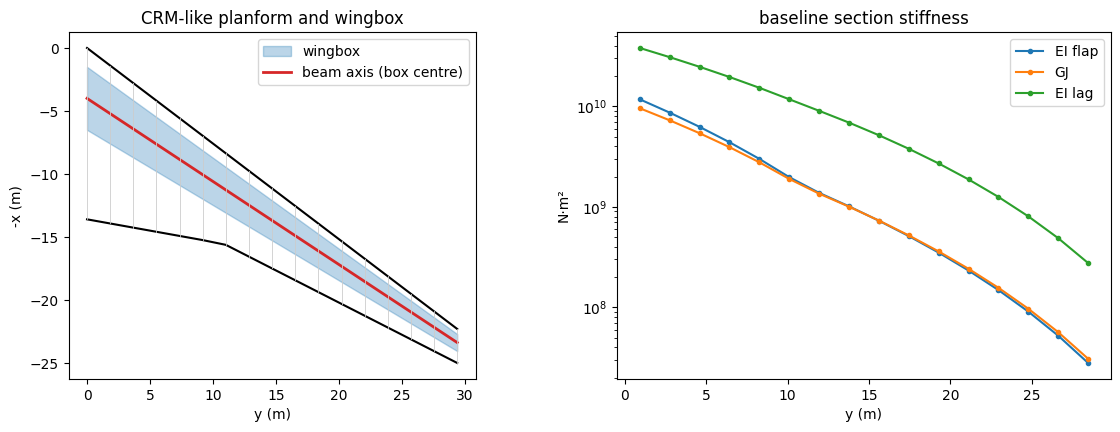

In [2]:
N = 16
wing = CRMWing(N, rho=1.225)
x0 = baseline_thickness(N)
g = planform(N)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ye = g["y_edges"]; eta_e = ye / SEMI_SPAN
c_e = np.interp(eta_e, [0, 0.37, 1], [13.6, 7.3, 2.7]); ct_e = 2.7 + (7.3 - 2.7) * (1 - eta_e) / (1 - 0.37)
xle = ye * np.tan(SWEEP_LE)
ax[0].plot(ye, -xle, "k"); ax[0].plot(ye, -(xle + c_e), "k")
ax[0].fill_between(ye, -(xle + FRONT_SPAR * ct_e), -(xle + REAR_SPAR * ct_e), color="C0", alpha=0.3, label="wingbox")
ax[0].plot(ye, -(xle + 0.4 * ct_e), "C3", lw=2, label="beam axis (box centre)")
for y_, xl_, c_ in zip(ye, xle, c_e): ax[0].plot([y_, y_], [-xl_, -(xl_ + c_)], color="0.8", lw=0.6)
ax[0].set_aspect("equal"); ax[0].set_xlabel("y (m)"); ax[0].set_ylabel("-x (m)"); ax[0].legend(); ax[0].set_title("CRM-like planform and wingbox")
p = wing.section_properties(x0)
for k, lab in [("EI_flap", "EI flap"), ("GJ", "GJ"), ("EI_lag", "EI lag")]:
    ax[1].semilogy(g["y"], p[k], "o-", ms=3, label=lab)
ax[1].set_xlabel("y (m)"); ax[1].set_ylabel("N·m²"); ax[1].legend(); ax[1].set_title("baseline section stiffness")
print(f"baseline wingbox mass = {float(wing.structural_mass(x0)):.0f} kg, total semi-span mass = {float(jnp.sum(p['mu'] * wing.seg_len)):.0f} kg")

### Reference modes (baseline design, in vacuo)
The six lowest modes are taken as references $\boldsymbol\phi_{r,i}$ and labelled from their shapes.

baseline: CriticalPoint(flutter: V=470.4806 m/s, f=9.0595 Hz)


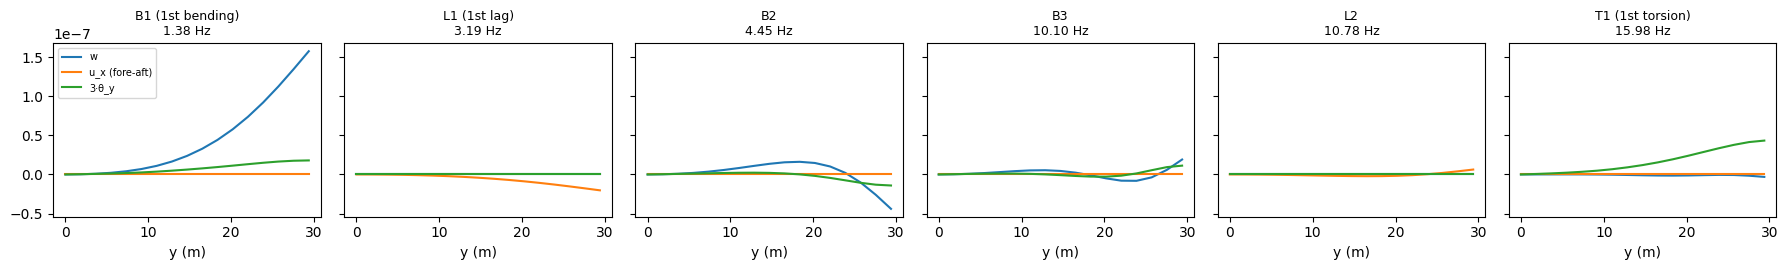

In [3]:
build_s = lambda x: wing.build(x, aero=gx.Aero.NONE)          # structural modes
build_V = lambda pv: wing.build(pv[0], pv[1])                # aeroelastic (Peters) at speed V
m0, f0 = build_s(x0)
res0 = gx.modal_analysis(m0, f0)
LABELS = ["B1 (1st bending)", "L1 (1st lag)", "B2", "B3", "L2", "T1 (1st torsion)"]
ref = tk.reference_modes(m0, res0, 6, LABELS)
fig, axs = plt.subplots(1, 6, figsize=(18, 2.8), sharey=True)
y_nodes = np.asarray(gx.node_positions(m0))[:, 1]
for i, ax in enumerate(axs):
    u, th = gx.mode_shape(m0, res0.right[:, res0.oscillatory()[i]])
    ax.plot(y_nodes, u[:, 2], label="w"); ax.plot(y_nodes, u[:, 0], label="u_x (fore-aft)")
    ax.plot(y_nodes, th[:, 1] * 3, label="3·θ_y")
    ax.set_title(f"{LABELS[i]}\n{ref.freq_hz[i]:.2f} Hz", fontsize=9); ax.set_xlabel("y (m)")
axs[0].legend(fontsize=7); plt.tight_layout()
pf0 = gx.flutter_speed(*wing.build(x0), 100, 700, n_grid=25, fmax_hz=30.0)
print("baseline:", pf0)

## 2. Why tracking: a mode crossing
Thin the spar webs progressively (skins unchanged). Lag and torsion stiffness drop faster than bending stiffness, so the L2 and B3
frequencies cross. Grey: frequencies sorted in ascending order; colour: modes tracked by MAC against the references.

B3 and L2 swap places in the sorted list at spar factor ≈ 0.564


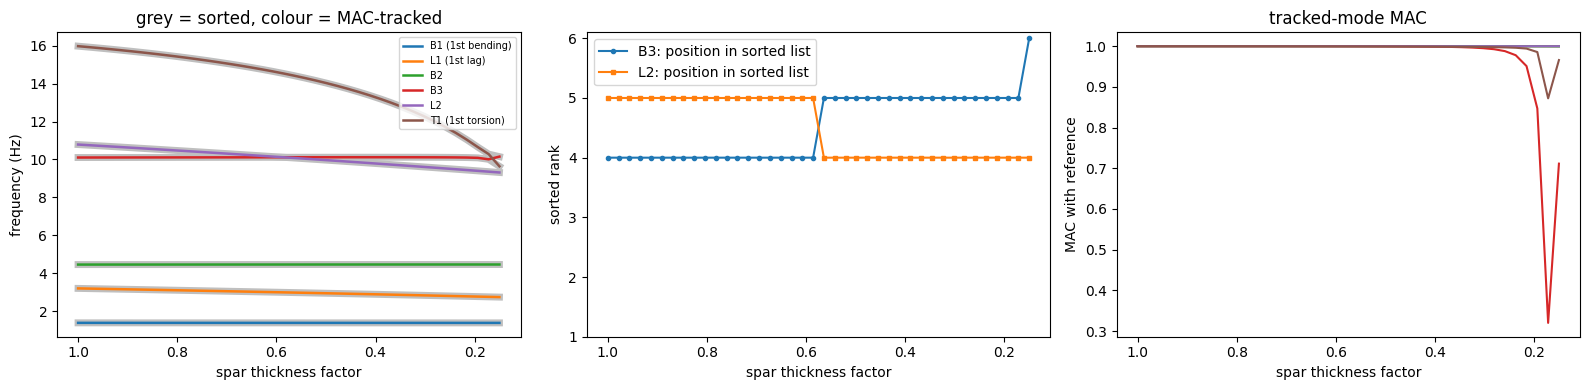

In [4]:
svals = np.linspace(1.0, 0.15, 40)
f_sorted, f_tracked, ranks, macs = [], [], [], []
for sv in svals:
    x = jnp.concatenate([x0[:N], x0[N:] * sv])
    m, f = build_s(x); r = gx.modal_analysis(m, f); tr = tk.track(m, r, ref, fmax_hz=30.0)
    f_sorted.append(r.freq_hz[r.oscillatory()[:6]]); f_tracked.append(tr.freq_hz); ranks.append(tr.sorted_rank); macs.append(tr.mac)
f_sorted, f_tracked, ranks, macs = map(np.array, (f_sorted, f_tracked, ranks, macs))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(svals, f_sorted, color="0.75", lw=5)
for i in range(6): ax[0].plot(svals, f_tracked[:, i], lw=1.8, label=LABELS[i])
ax[0].invert_xaxis(); ax[0].set_xlabel("spar thickness factor"); ax[0].set_ylabel("frequency (Hz)"); ax[0].legend(fontsize=7)
ax[0].set_title("grey = sorted, colour = MAC-tracked")
ax[1].plot(svals, ranks[:, 3] + 1, "o-", ms=3, label="B3: position in sorted list")
ax[1].plot(svals, ranks[:, 4] + 1, "s-", ms=3, label="L2: position in sorted list"); ax[1].invert_xaxis()
ax[1].set_xlabel("spar thickness factor"); ax[1].set_ylabel("sorted rank"); ax[1].legend(); ax[1].set_yticks(range(1, 7))
ax[2].plot(svals, macs); ax[2].invert_xaxis(); ax[2].set_xlabel("spar thickness factor"); ax[2].set_ylabel("MAC with reference")
ax[2].set_title("tracked-mode MAC"); plt.tight_layout()
k = int(np.argmax(ranks[:, 3] != 3))
print(f"B3 and L2 swap places in the sorted list at spar factor ≈ {svals[k]:.3f}")

The figure shows both situations discussed in `sensitivity_modetracking.ipynb` §3.1:

* **Crossing** (L2/B3, spar factor ≈ 0.56): the two modes barely interact, so their shapes do not change (MAC ≈ 1) while they swap places in the
  sorted list. Tracking follows each shape and the tracked frequency stays smooth.
* **Veering** (B3/T1, spar factor ≲ 0.2): the modes couple, their shapes genuinely mix, and the MAC with the references drops. Here no labelling
  is unambiguous and tracked-mode gradients lose meaning. This is precisely why a MAC-loss constraint is useful in optimisation: it keeps the design
  away from such zones.

A constraint written on "the 4th sorted frequency" would jump from B3 to L2 at the crossing (a discontinuous constraint with a
meaningless gradient). The tracked B3 frequency stays smooth, and its adjoint derivative along the path (chain rule
$\frac{df}{d\sigma}=\nabla_{\mathbf x}f\cdot\frac{d\mathbf x}{d\sigma}$) follows the slope of the tracked curve:

In [5]:
dxds = jnp.concatenate([jnp.zeros(N), x0[N:]])
sig_chk = [0.9, svals[k] + 0.05, svals[k] - 0.05, 0.3]
for sv in sig_chk:
    x = jnp.concatenate([x0[:N], x0[N:] * sv])
    ts = tk.tracked_sensitivities(build_s, x, ref, fmax_hz=30.0)
    d_adj = float(np.dot(ts.dfreq[3], dxds))
    h = 1e-4
    fp = tk.track(*(lambda mf: (mf[0], gx.modal_analysis(*mf)))(build_s(jnp.concatenate([x0[:N], x0[N:] * (sv + h)]))), ref, 30.0).freq_hz[3]
    fm = tk.track(*(lambda mf: (mf[0], gx.modal_analysis(*mf)))(build_s(jnp.concatenate([x0[:N], x0[N:] * (sv - h)]))), ref, 30.0).freq_hz[3]
    print(f"σ = {sv:.3f}: tracked B3 = {ts.freq_hz[3]:.4f} Hz (sorted rank {ts.tracked.sorted_rank[3] + 1}),  d f_B3/dσ adjoint = {d_adj:.5f},  FD = {(fp - fm) / (2 * h):.5f}")

σ = 0.900: tracked B3 = 10.1029 Hz (sorted rank 4),  d f_B3/dσ adjoint = -0.03224,  FD = -0.03226


σ = 0.614: tracked B3 = 10.1113 Hz (sorted rank 4),  d f_B3/dσ adjoint = -0.02529,  FD = -0.02530


σ = 0.514: tracked B3 = 10.1136 Hz (sorted rank 5),  d f_B3/dσ adjoint = -0.01819,  FD = -0.01824


σ = 0.300: tracked B3 = 10.1125 Hz (sorted rank 5),  d f_B3/dσ adjoint = 0.05717,  FD = 0.05724


## 3. Verification of the adjoint gradients
At a perturbed design (so that the shapes differ from the references), compare He-type adjoint gradients with converged central
differences ($h=10^{-4}$ on thicknesses of a few mm) and, for the frequencies, with the classical left/right-eigenvector formula.

In [6]:
rng = np.random.default_rng(0)
x1 = x0 * jnp.asarray((1 + 0.3 * rng.standard_normal(2 * N)).clip(0.3))
t = time.time(); ts1 = tk.tracked_sensitivities(build_s, x1, ref, fmax_hz=30.0); t_first = time.time() - t
t = time.time(); ts1 = tk.tracked_sensitivities(build_s, x1, ref, fmax_hz=30.0); t_adj = time.time() - t
print(f"MAC loss f = {ts1.mac_loss:.5f}, tracked MAC = {np.round(ts1.tracked.mac, 4)}")
print(f"adjoint gradients of f and of the 6 tracked frequencies (32 variables): {t_adj:.2f} s  (first call incl. JIT: {t_first:.1f} s)")

def loss_freq(x):
    m, f = build_s(jnp.asarray(x)); tr = tk.track(m, gx.modal_analysis(m, f), ref, 30.0)
    return 1 - tr.mac.mean(), tr.freq_hz

from gebtaero_jax.stability import eigenvalue_gradient
m1, f1 = build_s(x1); r1 = gx.modal_analysis(m1, f1); j6 = ts1.tracked.index[5]
_, _, im_p, _ = eigenvalue_gradient(lambda p, V: build_s(p), x1, 0.0, r1.eigvals[j6], r1.right[:, j6], r1.left[:, j6])
print(f"\n{'var':>4} | {'df/dx adjoint':>14} {'FD':>14} | {'dfT1/dx adjoint':>15} {'FD':>12} {'left/right':>12}")
for kk in [0, 6, 13, N + 2, N + 9, 2 * N - 1]:
    e = np.zeros(2 * N); e[kk] = 1e-5   # 0.01 mm: converged central-difference step
    lp, fp = loss_freq(np.asarray(x1) + e); lm, fm = loss_freq(np.asarray(x1) - e)
    print(f"{kk:4d} | {ts1.dmac_loss[kk]:14.6e} {(lp - lm) / (2 * e[kk]):14.6e} | {ts1.dfreq[5][kk]:15.6e} {(fp[5] - fm[5]) / (2 * e[kk]):12.6e} {np.asarray(im_p)[kk] / (2 * np.pi):12.6e}")

MAC loss f = 0.01211, tracked MAC = [0.996  0.9991 0.9876 0.9818 0.9964 0.9665]
adjoint gradients of f and of the 6 tracked frequencies (32 variables): 0.54 s  (first call incl. JIT: 0.5 s)



 var |  df/dx adjoint             FD | dfT1/dx adjoint           FD   left/right


   0 |   3.117499e-01   3.117472e-01 |    5.148289e+00 5.148417e+00 5.148289e+00


   6 |   4.827732e-02   4.829125e-02 |    1.022405e+01 1.022445e+01 1.022405e+01


  13 |  -8.702130e-01  -8.702111e-01 |    4.020467e+00 4.020514e+00 4.020467e+00


  18 |   7.597213e-02   7.596902e-02 |    6.136047e+00 6.136268e+00 6.136047e+00


  25 |  -1.942741e-02  -1.942959e-02 |    1.513914e+01 1.513910e+01 1.513914e+01


  31 |   1.575147e-01   1.575125e-01 |   -2.424824e+00 -2.424827e+00 -2.424824e+00


Flutter speed: the critical eigenpair is the bordered system's solution at $V_f$; one adjoint gives $\partial\Re s/\partial\mathbf p$ and $\partial\Re s/\partial V$.

In [7]:
xh = x0 * 0.5
pfh = gx.flutter_speed(*wing.build(xh), 150, 600, n_grid=10, fmax_hz=30.0, tol=1e-7)
_ = tk.flutter_gradient_adjoint(build_V, xh, pfh.velocity, pfh.eigval, fmax_hz=30.0)          # compile
t = time.time(); dVf, dff, _ = tk.flutter_gradient_adjoint(build_V, xh, pfh.velocity, pfh.eigval, fmax_hz=30.0); t_fl = time.time() - t
print(pfh, f"  adjoint gradient (32 variables) in {t_fl:.2f} s")
for kk in [0, 7, N + 2, 2 * N - 1]:
    e = np.zeros(2 * N); e[kk] = 1e-5
    vp = gx.flutter_speed(*wing.build(xh + e), pfh.velocity - 5, pfh.velocity + 5, n_grid=3, fmax_hz=30.0, tol=1e-8).velocity
    vm = gx.flutter_speed(*wing.build(xh - e), pfh.velocity - 5, pfh.velocity + 5, n_grid=3, fmax_hz=30.0, tol=1e-8).velocity
    print(f"  dV_f/dx[{kk:2d}]  adjoint = {dVf[kk]:10.4f}   FD = {(vp - vm) / 2e-5:10.4f}  (m/s per m)")

CriticalPoint(flutter: V=324.3930 m/s, f=7.0801 Hz)   adjoint gradient (32 variables) in 0.53 s


  dV_f/dx[ 0]  adjoint =   169.7655   FD =   169.7482  (m/s per m)


  dV_f/dx[ 7]  adjoint =   749.2272   FD =   749.1674  (m/s per m)


  dV_f/dx[18]  adjoint =   135.2818   FD =   135.2714  (m/s per m)


  dV_f/dx[31]  adjoint =   209.7761   FD =   209.8183  (m/s per m)


## 4. Cost versus number of design variables
Refining the spanwise segmentation increases both $n_x=2N$ and the model size. The adjoint cost is one modal analysis plus
$n_r$ bordered solves and one batched reverse pass; finite differences need $2n_x$ modal analyses (central). FD times are
*estimated* as $2n_x\times$ the measured time of one analysis (running them is pointless).

n_x =  16: adjoint   0.22 s  vs  FD ≈     3.1 s   (ratio  14.4)
n_x =  24: adjoint   0.45 s  vs  FD ≈    10.6 s   (ratio  23.3)
n_x =  32: adjoint   0.48 s  vs  FD ≈    17.0 s   (ratio  35.4)
n_x =  48: adjoint   0.86 s  vs  FD ≈    54.3 s   (ratio  63.1)


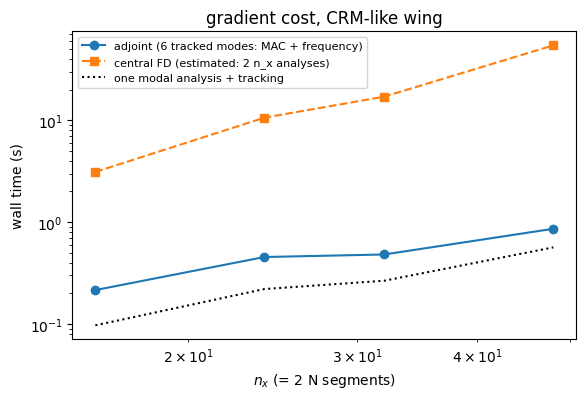

In [8]:
Ns = [8, 12, 16, 24]
t_an, t_ad = [], []
for n_ in Ns:
    w_ = CRMWing(n_, rho=1.225); xb = baseline_thickness(n_); bs = lambda x, w_=w_: w_.build(x, aero=gx.Aero.NONE)
    m_, f_ = bs(xb); ref_ = tk.reference_modes(m_, gx.modal_analysis(m_, f_), 6)
    xp = xb * 0.8
    tk.tracked_sensitivities(bs, xp, ref_, fmax_hz=30.0)                  # compile
    t = time.time(); tk.tracked_sensitivities(bs, xp, ref_, fmax_hz=30.0); t_ad.append(time.time() - t)
    t = time.time(); m_, f_ = bs(xp); tk.track(m_, gx.modal_analysis(m_, f_), ref_, 30.0); t_an.append(time.time() - t)
nx = 2 * np.array(Ns)
plt.figure(figsize=(6.5, 4))
plt.loglog(nx, t_ad, "o-", label="adjoint (6 tracked modes: MAC + frequency)")
plt.loglog(nx, 2 * nx * np.array(t_an), "s--", label="central FD (estimated: 2 n_x analyses)")
plt.loglog(nx, t_an, "k:", label="one modal analysis + tracking")
plt.xlabel("$n_x$ (= 2 N segments)"); plt.ylabel("wall time (s)"); plt.legend(fontsize=8); plt.title("gradient cost, CRM-like wing")
for n_, a, b in zip(nx, t_ad, t_an):
    print(f"n_x = {n_:3d}: adjoint {a:6.2f} s  vs  FD ≈ {2 * n_ * b:7.1f} s   (ratio {2 * n_ * b / a:5.1f})")

## 5. Gradient-based wingbox sizing with tracked-mode constraints

$$\min_{\mathbf t}\ m_{box}(\mathbf t)\quad\text{s.t.}\quad V_f\ge 300\ \text{m/s},\quad f_{B1}\ge 0.9\ \text{Hz},\quad f_{T1}\ge 9\ \text{Hz},\quad
f_{MAC}=1-\tfrac{1}{6}\textstyle\sum_i \mathrm{MAC}(\boldsymbol\phi_{r,i},\boldsymbol\phi_i)\le 0.02,\quad 3\le t\le 40\ \text{mm}.$$

* $f_{B1}$, $f_{T1}$ are **tracked** frequencies (the modes whose shapes match B1 and T1 of the baseline), not the 1st and 6th sorted ones.
* The MAC-loss constraint is He's loss: it keeps the low-frequency mode shapes close to the baseline (e.g. to keep a flight-control or
  load model valid), and it is what makes the tracking well-posed during the whole optimisation.
* All gradients come from the adjoint: 6 bordered solves (MAC and frequency share each LU) + 1 for the flutter speed, whatever $n_x$.
* Each design evaluation: one modal analysis, one flutter search in a window around the previous flutter speed, the adjoints.

In [9]:
V_REQ, F_B1, F_T1, EPS = 300.0, 0.9, 9.0, 0.02
mass_fn = jax.jit(wing.structural_mass); dmass_fn = jax.jit(jax.grad(wing.structural_mass))
cache, history = {}, []
state = {"V": pf0.velocity}

def flutter(x):
    Vg = state["V"]; m, f = wing.build(x)
    p = gx.flutter_speed(m, f, 0.85 * Vg, 1.25 * Vg, n_grid=5, fmax_hz=30.0, tol=1e-6)
    if not p.found:                                   # left the window: full search
        p = gx.flutter_speed(m, f, 100.0, 800.0, n_grid=15, fmax_hz=30.0, tol=1e-6)
    return p

def evaluate(z):                                      # z: thicknesses in mm
    key = tuple(np.round(z, 12))
    if key not in cache:
        t = time.time(); x = jnp.asarray(z * 1e-3)
        ts = tk.tracked_sensitivities(build_s, x, ref, fmax_hz=30.0)
        p = flutter(x); state["V"] = p.velocity
        dV, _, _ = tk.flutter_gradient_adjoint(build_V, x, p.velocity, p.eigval, fmax_hz=30.0)
        cache[key] = dict(V=p.velocity, dV=np.asarray(dV) * 1e-3, f=ts.freq_hz, df=[np.asarray(d) * 1e-3 for d in ts.dfreq],
                          loss=ts.mac_loss, dloss=np.asarray(ts.dmac_loss) * 1e-3, rank=ts.tracked.sorted_rank, mac=ts.tracked.mac,
                          mass=float(mass_fn(x)), time=time.time() - t)
        history.append(cache[key])
    return cache[key]

cons = [
    {"type": "ineq", "fun": lambda z: evaluate(z)["V"] / V_REQ - 1, "jac": lambda z: evaluate(z)["dV"] / V_REQ},
    {"type": "ineq", "fun": lambda z: evaluate(z)["f"][0] / F_B1 - 1, "jac": lambda z: evaluate(z)["df"][0] / F_B1},
    {"type": "ineq", "fun": lambda z: evaluate(z)["f"][5] / F_T1 - 1, "jac": lambda z: evaluate(z)["df"][5] / F_T1},
    {"type": "ineq", "fun": lambda z: 1 - evaluate(z)["loss"] / EPS, "jac": lambda z: -evaluate(z)["dloss"] / EPS},
]
obj = lambda z: float(mass_fn(jnp.asarray(z * 1e-3))) / 1e3
dobj = lambda z: np.asarray(dmass_fn(jnp.asarray(z * 1e-3))) * 1e-6
t0 = time.time()
opt = scipy.optimize.minimize(obj, np.asarray(x0) * 1e3, jac=dobj, constraints=cons, bounds=[(3.0, 40.0)] * (2 * N),
                              method="SLSQP", options={"maxiter": 30, "ftol": 1e-5})
t_opt = time.time() - t0
z_opt = opt.x; ev = evaluate(z_opt)
np.save("crm_optimum_thickness_mm.npy", z_opt)
print(opt.message, f"| {opt.nit} iterations, {len(history)} design evaluations, {t_opt / 60:.1f} min "
      f"(mean {np.mean([h['time'] for h in history]):.1f} s per evaluation incl. all gradients)")
print(f"box mass: {history[0]['mass']:.0f} kg -> {ev['mass']:.0f} kg  ({100 * (1 - ev['mass'] / history[0]['mass']):.1f} % lighter)")
print(f"V_f = {ev['V']:.2f} m/s, f_B1 = {ev['f'][0]:.4f} Hz, f_T1 = {ev['f'][5]:.4f} Hz, MAC loss = {ev['loss']:.4f}")
print("tracked MAC:", np.round(ev["mac"], 4), " sorted rank of the tracked modes:", ev["rank"] + 1)

Iteration limit reached | 30 iterations, 31 design evaluations, 6.4 min (mean 12.3 s per evaluation incl. all gradients)
box mass: 12482 kg -> 4170 kg  (66.6 % lighter)
V_f = 299.97 m/s, f_B1 = 0.9000 Hz, f_T1 = 10.4041 Hz, MAC loss = 0.0108
tracked MAC: [0.9955 0.9952 0.9925 0.9926 0.9935 0.9657]  sorted rank of the tracked modes: [1 2 3 4 5 6]


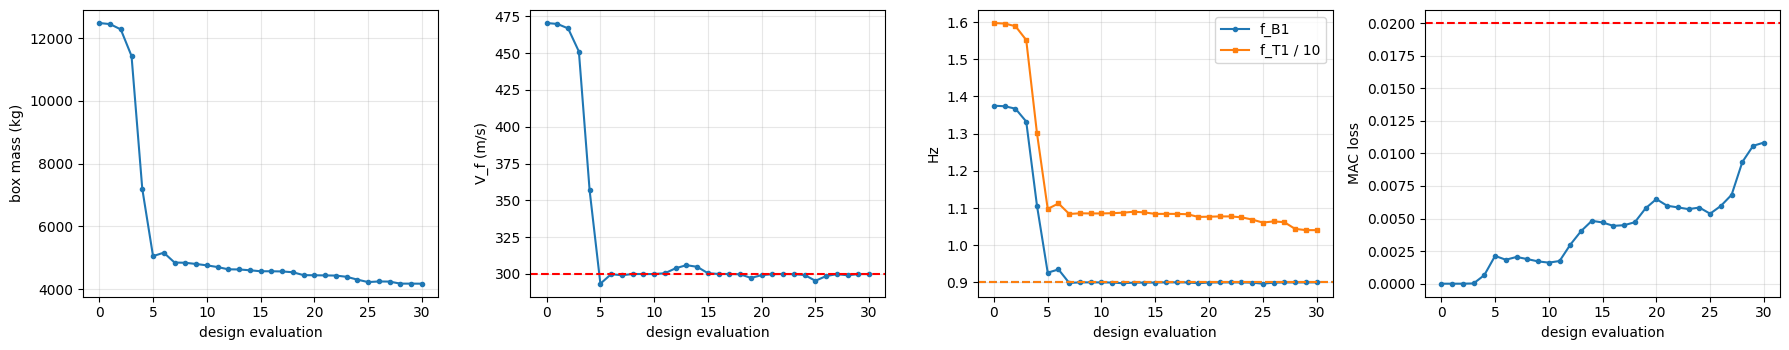

In [10]:
it = np.arange(len(history))
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
axs[0].plot(it, [h["mass"] for h in history], "o-", ms=3); axs[0].set_ylabel("box mass (kg)")
axs[1].plot(it, [h["V"] for h in history], "o-", ms=3); axs[1].axhline(V_REQ, color="r", ls="--"); axs[1].set_ylabel("V_f (m/s)")
axs[2].plot(it, [h["f"][0] for h in history], "o-", ms=3, label="f_B1"); axs[2].axhline(F_B1, color="C0", ls="--")
axs[2].plot(it, [h["f"][5] / 10 for h in history], "s-", ms=3, label="f_T1 / 10"); axs[2].axhline(F_T1 / 10, color="C1", ls="--")
axs[2].set_ylabel("Hz"); axs[2].legend()
axs[3].plot(it, [h["loss"] for h in history], "o-", ms=3); axs[3].axhline(EPS, color="r", ls="--"); axs[3].set_ylabel("MAC loss")
for a in axs: a.set_xlabel("design evaluation"); a.grid(alpha=.3)
plt.tight_layout()

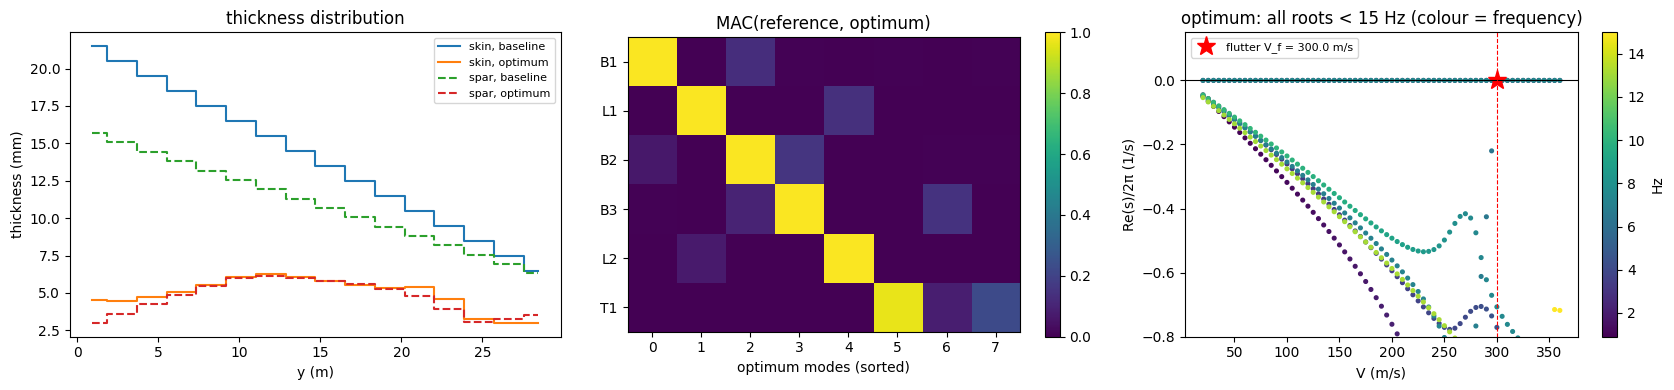

In [11]:
x_opt = jnp.asarray(z_opt * 1e-3)
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
axs[0].step(g["y"], np.asarray(x0[:N]) * 1e3, where="mid", label="skin, baseline"); axs[0].step(g["y"], z_opt[:N], where="mid", label="skin, optimum")
axs[0].step(g["y"], np.asarray(x0[N:]) * 1e3, where="mid", ls="--", label="spar, baseline"); axs[0].step(g["y"], z_opt[N:], where="mid", ls="--", label="spar, optimum")
axs[0].set_xlabel("y (m)"); axs[0].set_ylabel("thickness (mm)"); axs[0].legend(fontsize=8); axs[0].set_title("thickness distribution")
mo, fo = build_s(x_opt); ro = gx.modal_analysis(mo, fo); tro = tk.track(mo, ro, ref, 30.0)
im = axs[1].imshow(tro.mac_full[:, :8], vmin=0, vmax=1, cmap="viridis")
axs[1].set_yticks(range(6)); axs[1].set_yticklabels([l.split(" ")[0] for l in LABELS]); axs[1].set_xlabel("optimum modes (sorted)")
axs[1].set_title("MAC(reference, optimum)"); plt.colorbar(im, ax=axs[1])
mf_opt = wing.build(x_opt); pts = []
for V in np.linspace(20, 360, 69):            # all roots below 15 Hz (no tracking needed for this view)
    r = gx.modal_analysis(mf_opt[0], mf_opt[1].replace(velocity=V)); i = r.oscillatory(); i = i[r.freq_hz[i] < 15]
    pts += [(V, r.damping[j], r.freq_hz[j]) for j in i]
pts = np.array(pts)
sc = axs[2].scatter(pts[:, 0], pts[:, 1], c=pts[:, 2], s=7, cmap="viridis")
axs[2].plot([ev["V"]], [0.0], "r*", ms=14, label=f"flutter V_f = {ev['V']:.1f} m/s")
axs[2].axhline(0, color="k", lw=0.8); axs[2].axvline(V_REQ, color="r", ls="--", lw=0.8)
axs[2].set_ylim(-0.8, 0.15); axs[2].set_xlabel("V (m/s)"); axs[2].set_ylabel("Re(s)/2π (1/s)")
axs[2].set_title("optimum: all roots < 15 Hz (colour = frequency)"); axs[2].legend(fontsize=8)
plt.colorbar(sc, ax=axs[2], label="Hz")
plt.tight_layout()

## Summary

* He's bordered eigen-adjoint carries over to the complex, non-symmetric pencil of the geometrically exact beam with an analytic
  normalisation and a real split; the partials $\boldsymbol\psi^T\partial\mathbf r/\partial\mathbf x$ come matrix-free from AD.
* Gradients of the MAC loss, of every tracked frequency and of the flutter speed agree with the left/right-eigenvector formula to
  machine precision and with converged finite differences to FD accuracy. Their cost does not grow with $n_x$, while FD grows like $2n_x$
  analyses (and FD on eigenvectors needs carefully chosen steps: $h=10^{-7}$ m gives 10 % errors here).
* Tracking keeps constraints attached to physical modes through crossings (spar-thinning example).
* The tracked-mode constrained sizing removes about two thirds of the (deliberately over-designed) wingbox mass with $V_f$ and $f_{B1}$ active,
  at about one flutter analysis per design evaluation. SLSQP stops at its 30-iteration limit; a longer run gains less than 1 % more.
* The optimum puts *less* material at the root than at mid-span: with only aeroelastic and modal constraints, stiffness near the root matters
  less for these modes than the mass it adds. A real sizing would add stress, buckling and manoeuvre/gust-load constraints (their adjoints fit
  the same pattern, via `solve_static`'s implicit differentiation).

**Limits.** Simplified wingbox (no stress, buckling or manoeuvre-load constraints, no engine or fuel-state cases), incompressible strip
aerodynamics, and gradients defined only while each tracked mode stays simple and its MAC pairing does not switch (veering zones).